In [2]:
import pandas as pd
import numpy as np
from datetime import datetime, time, timedelta

def generate_comprehensive_attendance_dataset():
    # Set random seed for reproducibility
    np.random.seed(42)
    
    start_date = datetime(2026, 6, 17)
    end_date = datetime(2026, 8, 17)
    
    # Generate operational dates (excluding Sundays)
    current_date = start_date
    dates = []
    while current_date <= end_date:
        if current_date.weekday() != 6: # Exclude Sunday
            dates.append(current_date)
        current_date += timedelta(days=1)
        
    muharram_date = datetime(2026, 6, 26)
    
    subjects_sec_a = ['Python', 'DBMS', 'Web Tech', 'Industry Readiness Program', 'Data Structures']
    subjects_sec_b = ['Python', 'DBMS', 'Java', 'Operating Systems', 'Software Eng']
    
    lecture_times = [
        (time(9, 15), time(10, 15)),
        (time(10, 15), time(11, 15)),
        (time(11, 30), time(12, 30)),
        (time(13, 30), time(14, 30))
    ]
    
    records = []
    
    for d in dates:
        if d == muharram_date:
            continue # Skip Muharram holiday on 26th June 2026
            
        day_name = d.strftime('%A')
        is_test_week = 'Yes' if 10 <= d.day <= 14 and d.month == 7 else 'No'
        holiday_near = 'Yes' if day_name == 'Saturday' or (d.day == 15 and d.month == 8) else 'No'
        
        for section, total_stud, subs in [('A', 103, subjects_sec_a), ('B', 102, subjects_sec_b)]:
            prev_perc = 78.0
            
            for l_idx in range(4): # 4 lectures per day per section
                start_t, end_t = lecture_times[l_idx]
                
                sub = np.random.choice(subs)
                faculty_id = f"F_{section}_{l_idx+1}"
                if sub == 'Industry Readiness Program':
                    faculty_id = 'Sohan Dadarkar'
                    
                is_special = 'No'
                practical_theory = 'Theory' if l_idx < 3 else 'Practical'
                
                # Custom Timetable & Guest Session Injection Rules
                if d >= datetime(2026, 7, 13) and d <= datetime(2026, 8, 13) and day_name == 'Monday' and l_idx == 1:
                    sub = 'Innovation and Entrepreneurship Development'
                    faculty_id = 'Sopan Aghav Sir'
                    is_special = 'Yes'
                elif d >= datetime(2026, 7, 27) and d <= datetime(2026, 8, 7) and day_name in ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday'] and l_idx == 0:
                    sub = 'Selenium (STQA)'
                    faculty_id = 'Mr. Keshav Potdar'
                elif d >= datetime(2026, 8, 2) and start_t >= time(13, 30) and day_name in ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']:
                    sub = 'Cloud Computing (AWS)'
                    faculty_id = 'Mr. Kiran Nikam'
                elif d == datetime(2026, 8, 8) and l_idx == 0:
                    sub = 'AWS COMPUTE SERVICES'
                    faculty_id = 'Mr. Sarvesh Deshpande'
                    is_special = 'Yes'
                
                # Classroom Allocation Logic:
                # 403 for theory, Computer Lab for practicals, Seminar Hall for seminars/guest lectures
                if is_special == 'Yes' or 'Seminar' in sub or 'Guest' in sub:
                    classroom = 'Seminar Hall'
                elif practical_theory == 'Practical':
                    classroom = 'Computer Lab'
                else:
                    classroom = '403'
                
                # Attendance Percentage Modeling
                base_att = 76.0
                if day_name == 'Monday': base_att -= 8.0
                if day_name == 'Saturday': base_att -= 12.0
                if is_test_week == 'Yes': base_att += 6.0
                
                att_perc = np.clip(base_att + np.random.normal(0, 8), 35.0, 98.0)
                present_count = int(round((att_perc / 100.0) * total_stud))
                att_perc = round((present_count / total_stud) * 100.0, 2)
                
                records.append({
                    'Date': d.strftime('%Y-%m-%d'),
                    'Day of Week': day_name,
                    'Lecture Number': l_idx + 1,
                    'Start Time': start_t.strftime('%H:%M:%S'),
                    'End Time': end_t.strftime('%H:%M:%S'),
                    'Subject': sub,
                    'Faculty ID': faculty_id,
                    'Semester': 'III',
                    'Branch': 'MCA',
                    'Section': section,
                    'Classroom': classroom,
                    'Total Enrolled Students': total_stud,
                    'Students Present': present_count,
                    'Attendance Percentage': att_perc,
                    'Previous Lecture Attendance': round(prev_perc, 2),
                    'Gap Since Previous Lecture': 0.0 if l_idx == 0 else 1.0,
                    'Practical/Theory': practical_theory,
                    'Internal Test Week': is_test_week,
                    'Assignment Due': 'Yes' if np.random.rand() < 0.25 else 'No',
                    'Holiday Before/After': holiday_near,
                    'Weather': np.random.choice(['Sunny', 'Cloudy', 'Rainy'], p=[0.5, 0.3, 0.2]),
                    'Special Event': is_special,
                    'Faculty Experience': np.random.randint(3, 15),
                    'Week Number': (d - start_date).days // 7 + 1,
                    'Day of Semester': (d - start_date).days + 1,
                    'Time of Day': 'Morning' if start_t.hour < 12 else 'Afternoon'
                })
                prev_perc = att_perc
                
    df = pd.DataFrame(records)
    output_filename = "Final_MCA_Attendance_Dataset.xlsx"
    df.to_excel(output_filename, sheet_name='Attendance_Data', index=False)
    print(f"Dataset successfully generated with {len(df)} records and saved as {output_filename}!")

if __name__ == '__main__':
    generate_comprehensive_attendance_dataset()

Dataset successfully generated with 416 records and saved as Final_MCA_Attendance_Dataset.xlsx!


# Phase 2: Data Preprocessing & EDA
### This cell loads your generated Excel dataset and drops columns that are constant or would cause data leakage during training (such as the exact start/end times and the headcount).

--- Exploratory Data Analysis (EDA) ---


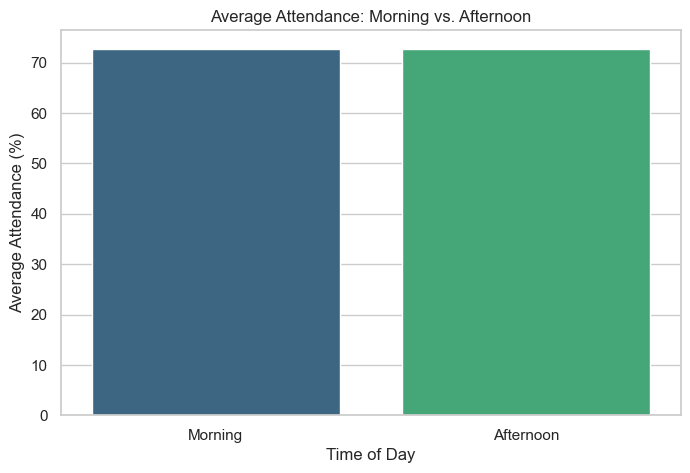

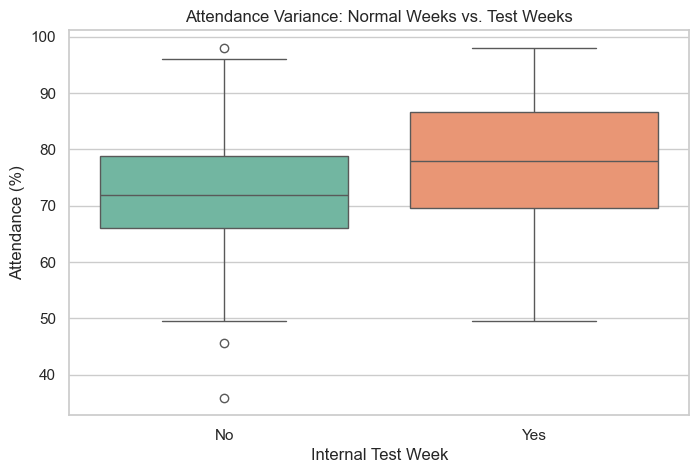


Subject-wise Average Attendance:
Subject
Selenium (STQA)                                74.89
Java                                           73.88
DBMS                                           73.44
Cloud Computing (AWS)                          73.36
Data Structures                                73.35
Operating Systems                              73.17
Python                                         73.13
Software Eng                                   72.62
Web Tech                                       71.79
Industry Readiness Program                     70.34
AWS COMPUTE SERVICES                           68.78
Innovation and Entrepreneurship Development    65.26
Name: Attendance Percentage, dtype: float64

Dataset loaded successfully. Shape: (416, 26)


,Day of Week,Lecture Number,Subject,Faculty ID,Section,Classroom,Total Enrolled Students,Previous Lecture Attendance,Gap Since Previous Lecture,Practical/Theory,Internal Test Week,Assignment Due,Holiday Before/After,Weather,Special Event,Faculty Experience,Week Number,Day of Semester,Time of Day
0,Wednesday,1,Industry Readiness Program,Sohan Dadarkar,A,403,103,78.00,0,Theory,No,Yes,No,Sunny,No,10,1,1,Morning
1,Wednesday,2,Data Structures,F_A_2,A,403,103,66.99,1,Theory,No,No,No,Cloudy,No,8,1,1,Morning
2,Wednesday,3,Data Structures,F_A_3,A,403,103,78.64,1,Theory,No,Yes,No,Sunny,No,8,1,1,Morning
3,Wednesday,4,Data Structures,F_A_4,A,Computer Lab,103,70.87,1,Practical,No,No,No,Sunny,No,13,1,1,Afternoon
4,Wednesday,1,DBMS,F_B_1,B,403,102,78.00,0,Theory,No,No,No,Sunny,No,6,1,1,Morning


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the generated Excel dataset
df = pd.read_excel('Final_MCA_Attendance_Dataset.xlsx', sheet_name='Attendance_Data')

# ==========================================
# --- EXPLORATORY DATA ANALYSIS (EDA) ---
# ==========================================
print("--- Exploratory Data Analysis (EDA) ---")

# Set visual style
sns.set_theme(style="whitegrid")

# EDA 1: Time of Day Trends
plt.figure(figsize=(8, 5))
sns.barplot(x='Time of Day', y='Attendance Percentage', data=df, errorbar=None, palette='viridis', hue='Time of Day', legend=False)
plt.title('Average Attendance: Morning vs. Afternoon')
plt.ylabel('Average Attendance (%)')
plt.show()

# EDA 2: Impact of Internal Tests
plt.figure(figsize=(8, 5))
sns.boxplot(x='Internal Test Week', y='Attendance Percentage', data=df, palette='Set2', hue='Internal Test Week', legend=False)
plt.title('Attendance Variance: Normal Weeks vs. Test Weeks')
plt.ylabel('Attendance (%)')
plt.show()

# EDA 3: Subject-wise Average Attendance
print("\nSubject-wise Average Attendance:")
subject_table = df.groupby('Subject')['Attendance Percentage'].mean().sort_values(ascending=False).round(2)
print(subject_table)
# ==========================================

# 2. Define the target variable
y = df['Attendance Percentage']

# 3. Drop non-predictive columns, constants, and data leakage features
columns_to_drop = [
    'Date', 'Start Time', 'End Time', 'Students Present', 
    'Attendance Percentage', 'Semester', 'Branch'
]
X = df.drop(columns=columns_to_drop, errors='ignore')

print(f"\nDataset loaded successfully. Shape: {df.shape}")
display(X.head())

# Phase 3: Categorical Encoding & Train-Test Split
### Machine learning models require numbers, not text. This cell applies Label Encoding to your "Yes/No" binary flags and One-Hot Encoding to your multi-class features (like Subject and Faculty ID).

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import joblib

# 1. Label Encode Binary Columns ('Yes'/'No')
le = LabelEncoder()
binary_cols = ['Internal Test Week', 'Assignment Due', 'Holiday Before/After', 'Special Event']
for col in binary_cols:
    if col in X.columns:
        X[col] = le.fit_transform(X[col])

# 2. One-Hot Encode Categorical Columns
categorical_cols = [
    'Day of Week', 'Subject', 'Faculty ID', 'Section', 
    'Classroom', 'Practical/Theory', 'Time of Day', 'Weather'
]
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=False)

# 3. Save the exact feature columns for the Streamlit dashboard
joblib.dump(X_encoded.columns.tolist(), 'model_features.pkl')

# 4. Train-Test Split (80% Training, 20% Testing)
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

print(f"Training Features Shape: {X_train.shape}")
print(f"Testing Features Shape: {X_test.shape}")

Training Features Shape: (332, 54)
Testing Features Shape: (84, 54)


# Phase 4: Model Training, Evaluation & Export
### To ensure your pipeline is fully complete, this final cell trains the regression algorithms, evaluates them using standard metrics (MAE, RMSE, R²), and serializes the best-performing model into a .pkl file for your web app.

In [8]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
import joblib

# 1. Initialize models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42),
    "XGBoost": xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

results = []

# 2. Train and Evaluate each model
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)
    
    results.append({
        "Algorithm": name,
        "R-Squared (R2)": round(r2, 4),
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2)
    })

# 3. Display Results Matrix
experiment_table = pd.DataFrame(results)
print("--- Model Performance Table ---")
display(experiment_table)

# 4. Export the Best Performing Model (XGBoost) for deployment
best_model = models["XGBoost"]
joblib.dump(best_model, 'mca_attendance_model.pkl')
print("\nSuccess! 'mca_attendance_model.pkl' and 'model_features.pkl' have been saved to your folder.")

--- Model Performance Table ---


,Algorithm,R-Squared (R2),MAE,RMSE
0,Linear Regression,0.3157,5.75,7.28
1,Random Forest,0.1727,6.26,8.01
2,Gradient Boosting,-0.0023,6.91,8.82
3,XGBoost,-0.1823,7.39,9.57



Success! 'mca_attendance_model.pkl' and 'model_features.pkl' have been saved to your folder.
